# SUMO Simulation Quickstart

## 1. Environment Check

In [20]:
import os
import sys
import shutil
import subprocess

import traci
import sumolib

# SUMO installation paths
SUMO_INSTALL = "/Library/Frameworks/EclipseSUMO.framework/Versions/Current/EclipseSUMO"
SUMO_HOME = os.path.join(SUMO_INSTALL, "share", "sumo")
SUMO_BIN = os.path.join(SUMO_INSTALL, "bin")

# Configure environment
os.environ["SUMO_HOME"] = SUMO_HOME
os.environ["PATH"] = SUMO_BIN + os.pathsep + os.environ["PATH"]

# Verify installation
print("Python:", sys.version.split()[0])
print("SUMO:", shutil.which("sumo"))
print("Netgenerate:", shutil.which("netgenerate"))
print("SUMO_HOME:", os.environ["SUMO_HOME"])

result = subprocess.run(
    ["sumo", "--version"],
    capture_output=True,
    text=True,
    check=True
)

print("SUMO version:", result.stdout.splitlines()[0])

Python: 3.11.17
SUMO: /Library/Frameworks/EclipseSUMO.framework/Versions/Current/EclipseSUMO/bin/sumo
Netgenerate: /Library/Frameworks/EclipseSUMO.framework/Versions/Current/EclipseSUMO/bin/netgenerate
SUMO_HOME: /Library/Frameworks/EclipseSUMO.framework/Versions/Current/EclipseSUMO/share/sumo
SUMO version: Eclipse SUMO sumo 1.28.0


## 2. Network Generation

In [8]:
from pathlib import Path
import subprocess

# Project paths
PROJECT_ROOT = Path.cwd().resolve().parent
SIM_ROOT = PROJECT_ROOT / "simulations"

A 3×3 grid consisting of nine intersections connected by 200 m road segments. Traffic signals are assigned automatically by SUMO.

```text
    ● ───── ● ───── ●
    │       │       │
    │       │       │
    ● ───── ● ───── ●
    │       │       │
    │       │       │
    ● ───── ● ───── ●

    ● Intersection
    ─ Road segment (200 m)
```

In [9]:
# Generate a 3x3 grid network
GRID_DIR = SIM_ROOT / "intersections"
GRID_DIR.mkdir(parents=True, exist_ok=True)

GRID_NET_FILE = GRID_DIR / "grid_3x3.net.xml"

subprocess.run(
    [
        "netgenerate",
        "--grid",
        "--grid.number", "3",
        "--grid.length", "200",
        "--tls.guess", "true",
        "--output-file", str(GRID_NET_FILE),
    ],
    check=True,
)

print(f"3x3 grid network created: {GRID_NET_FILE}")

Success.
3x3 grid network created: /Users/jiyoon/Desktop/git/informative-scenario-mining/simulations/intersections/grid_3x3.net.xml


A four-way intersection with a traffic signal at the center. Each approach has one incoming and one outgoing lane, with 200 m road segments and a speed limit of 50 km/h.

```text
                  North
                    ●
                    ║
                    ║
                    ║
 West ● ═══════════ ⊕ ═══════════ ● East
                    ║
                    ║
                    ║
                    ●
                  South

    ⊕  Signalized intersection
    ●  Road endpoint
    ═  Bidirectional road (200 m per approach)
```

In [10]:
# Generate a single signalized intersection
SINGLE_DIR = SIM_ROOT / "single_intersection"
SINGLE_DIR.mkdir(parents=True, exist_ok=True)

NODE_FILE = SINGLE_DIR / "single_intersection.nod.xml"
EDGE_FILE = SINGLE_DIR / "single_intersection.edg.xml"
SINGLE_NET_FILE = SINGLE_DIR / "single_intersection.net.xml"

# Define nodes
NODE_FILE.write_text("""<nodes>
    <node id="center" x="0" y="0" type="traffic_light"/>
    <node id="north" x="0" y="200"/>
    <node id="south" x="0" y="-200"/>
    <node id="east" x="200" y="0"/>
    <node id="west" x="-200" y="0"/>
</nodes>
""")

# Define edges
EDGE_FILE.write_text("""<edges>
    <edge id="north_in" from="north" to="center" numLanes="1" speed="13.89"/>
    <edge id="north_out" from="center" to="north" numLanes="1" speed="13.89"/>
    <edge id="south_in" from="south" to="center" numLanes="1" speed="13.89"/>
    <edge id="south_out" from="center" to="south" numLanes="1" speed="13.89"/>
    <edge id="east_in" from="east" to="center" numLanes="1" speed="13.89"/>
    <edge id="east_out" from="center" to="east" numLanes="1" speed="13.89"/>
    <edge id="west_in" from="west" to="center" numLanes="1" speed="13.89"/>
    <edge id="west_out" from="center" to="west" numLanes="1" speed="13.89"/>
</edges>
""")

# Convert to SUMO network
subprocess.run(
    [
        "netconvert",
        "--node-files", str(NODE_FILE),
        "--edge-files", str(EDGE_FILE),
        "--output-file", str(SINGLE_NET_FILE),
    ],
    check=True,
)

print(f"Single intersection network created: {SINGLE_NET_FILE}")

Success.
Single intersection network created: /Users/jiyoon/Desktop/git/informative-scenario-mining/simulations/single_intersection/single_intersection.net.xml



## 3. Traffic Demand Configuration

Define vehicle routes and departure times for the single signalized intersection.

For the initial test, vehicles travel straight through the intersection from all four directions.


In [11]:
# Define traffic demand for the single intersection
ROUTE_FILE = SINGLE_DIR / "single_intersection.rou.xml"

ROUTE_FILE.write_text("""<routes>
    <vType id="car" accel="2.6" decel="4.5"
           sigma="0.5" length="5" maxSpeed="13.89"/>

    <route id="north_south" edges="north_in south_out"/>
    <route id="south_north" edges="south_in north_out"/>
    <route id="east_west" edges="east_in west_out"/>
    <route id="west_east" edges="west_in east_out"/>

    <flow id="flow_ns" type="car" route="north_south"
          begin="0" end="600" vehsPerHour="300"/>

    <flow id="flow_sn" type="car" route="south_north"
          begin="0" end="600" vehsPerHour="300"/>

    <flow id="flow_ew" type="car" route="east_west"
          begin="0" end="600" vehsPerHour="300"/>

    <flow id="flow_we" type="car" route="west_east"
          begin="0" end="600" vehsPerHour="300"/>
</routes>
""")

print(f"Route file created: {ROUTE_FILE}")

Route file created: /Users/jiyoon/Desktop/git/informative-scenario-mining/simulations/single_intersection/single_intersection.rou.xml


In [12]:
# Create simulation configuration
CONFIG_FILE = SINGLE_DIR / "single_intersection.sumocfg"

CONFIG_FILE.write_text("""<configuration>
    <input>
        <net-file value="single_intersection.net.xml"/>
        <route-files value="single_intersection.rou.xml"/>
    </input>
    <time>
        <begin value="0"/>
        <end value="900"/>
    </time>
</configuration>
""")

print(f"Configuration created: {CONFIG_FILE}")

Configuration created: /Users/jiyoon/Desktop/git/informative-scenario-mining/simulations/single_intersection/single_intersection.sumocfg


## 4. Simulation Execution with TraCI

In [13]:
import traci
import pandas as pd

traci.start(["sumo", "-c", str(CONFIG_FILE)])

records = []

try:
    while traci.simulation.getMinExpectedNumber() > 0:
        traci.simulationStep()

        records.append({
            "time": traci.simulation.getTime(),
            "vehicles": traci.vehicle.getIDCount(),
            "waiting": sum(
                traci.edge.getLastStepHaltingNumber(edge)
                for edge in ["north_in", "south_in", "east_in", "west_in"]
            ),
        })
finally:
    traci.close()

df = pd.DataFrame(records)
display(df.head())

print("Simulation steps:", len(df))

 Retrying in 1 seconds


Step #653.00 (0ms ?*RT. ?UPS, TraCI: 0ms, vehicles TOT 200 ACT 0 BUF 0)                   


,time,vehicles,waiting
0,1.0,4,0
1,2.0,4,0
2,3.0,4,0
3,4.0,4,0
4,5.0,4,0


Simulation steps: 653


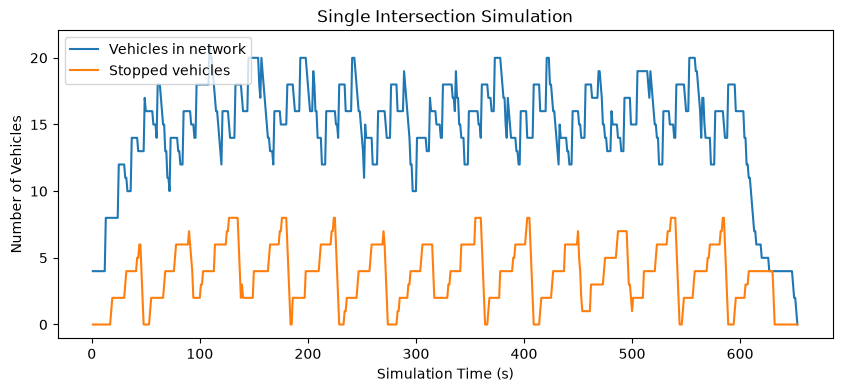

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(df["time"], df["vehicles"], label="Vehicles in network")
ax.plot(df["time"], df["waiting"], label="Stopped vehicles")

ax.set_xlabel("Simulation Time (s)")
ax.set_ylabel("Number of Vehicles")
ax.set_title("Single Intersection Simulation")
ax.legend()

plt.show()

In [16]:
import sumolib

net = sumolib.net.readNet(str(SINGLE_NET_FILE), withPrograms=True)

for tls in net.getTrafficLights():
    print("Traffic light:", tls.getID())

    for program in tls.getPrograms().values():
        for i, phase in enumerate(program.getPhases()):
            print(
                f"Phase {i}: "
                f"duration={phase.duration}s, "
                f"state={phase.state}"
            )

Traffic light: center
Phase 0: duration=42s, state=GGggrrrrGGggrrrr
Phase 1: duration=3s, state=yyyyrrrryyyyrrrr
Phase 2: duration=42s, state=rrrrGGggrrrrGGgg
Phase 3: duration=3s, state=rrrryyyyrrrryyyy


In [21]:
traci.start(["sumo", "-c", str(CONFIG_FILE)])

try:
    links = traci.trafficlight.getControlledLinks("center")

    for i, connections in enumerate(links):
        print(f"Signal {i}: {connections}")
finally:
    traci.close()

 Retrying in 1 seconds
Signal 0: (('north_in_0', 'west_out_0', ':center_0_0'),)
Signal 1: (('north_in_0', 'south_out_0', ':center_1_0'),)
Signal 2: (('north_in_0', 'east_out_0', ':center_2_0'),)
Signal 3: (('north_in_0', 'north_out_0', ':center_3_0'),)
Signal 4: (('east_in_0', 'north_out_0', ':center_4_0'),)
Signal 5: (('east_in_0', 'west_out_0', ':center_5_0'),)
Signal 6: (('east_in_0', 'south_out_0', ':center_6_0'),)
Signal 7: (('east_in_0', 'east_out_0', ':center_7_0'),)
Signal 8: (('south_in_0', 'east_out_0', ':center_8_0'),)
Signal 9: (('south_in_0', 'north_out_0', ':center_9_0'),)
Signal 10: (('south_in_0', 'west_out_0', ':center_10_0'),)
Signal 11: (('south_in_0', 'south_out_0', ':center_11_0'),)
Signal 12: (('west_in_0', 'south_out_0', ':center_12_0'),)
Signal 13: (('west_in_0', 'east_out_0', ':center_13_0'),)
Signal 14: (('west_in_0', 'north_out_0', ':center_14_0'),)
Signal 15: (('west_in_0', 'west_out_0', ':center_15_0'),)
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 2ms, vehicles TOT 

In [24]:
import traci
import pandas as pd

traci.start(["sumo", "-c", str(CONFIG_FILE)])

records = []

try:
    while traci.simulation.getMinExpectedNumber() > 0:
        traci.simulationStep()

        records.append({
            "time": traci.simulation.getTime(),
            "phase": traci.trafficlight.getPhase("center"),
            "north": traci.edge.getLastStepHaltingNumber("north_in"),
            "south": traci.edge.getLastStepHaltingNumber("south_in"),
            "east": traci.edge.getLastStepHaltingNumber("east_in"),
            "west": traci.edge.getLastStepHaltingNumber("west_in"),
        })

finally:
    traci.close()

df_signal = pd.DataFrame(records)

df_signal["NS_waiting"] = df_signal["north"] + df_signal["south"]
df_signal["EW_waiting"] = df_signal["east"] + df_signal["west"]

display(df_signal.head(20))

 Retrying in 1 seconds
Step #653.00 (0ms ?*RT. ?UPS, TraCI: 0ms, vehicles TOT 200 ACT 0 BUF 0)                   


,time,phase,north,south,east,west,NS_waiting,EW_waiting
0,1.0,0,0,0,0,0,0,0
1,2.0,0,0,0,0,0,0,0
2,3.0,0,0,0,0,0,0,0
3,4.0,0,0,0,0,0,0,0
4,5.0,0,0,0,0,0,0,0
5,6.0,0,0,0,0,0,0,0
6,7.0,0,0,0,0,0,0,0
7,8.0,0,0,0,0,0,0,0
8,9.0,0,0,0,0,0,0,0
9,10.0,0,0,0,0,0,0,0


In [25]:
df_signal[["NS_waiting", "EW_waiting"]].describe()

,NS_waiting,EW_waiting
count,653.000000,653.000000
mean,1.851455,1.836141
std,2.411180,2.432357
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,4.000000,4.000000
max,8.000000,8.000000


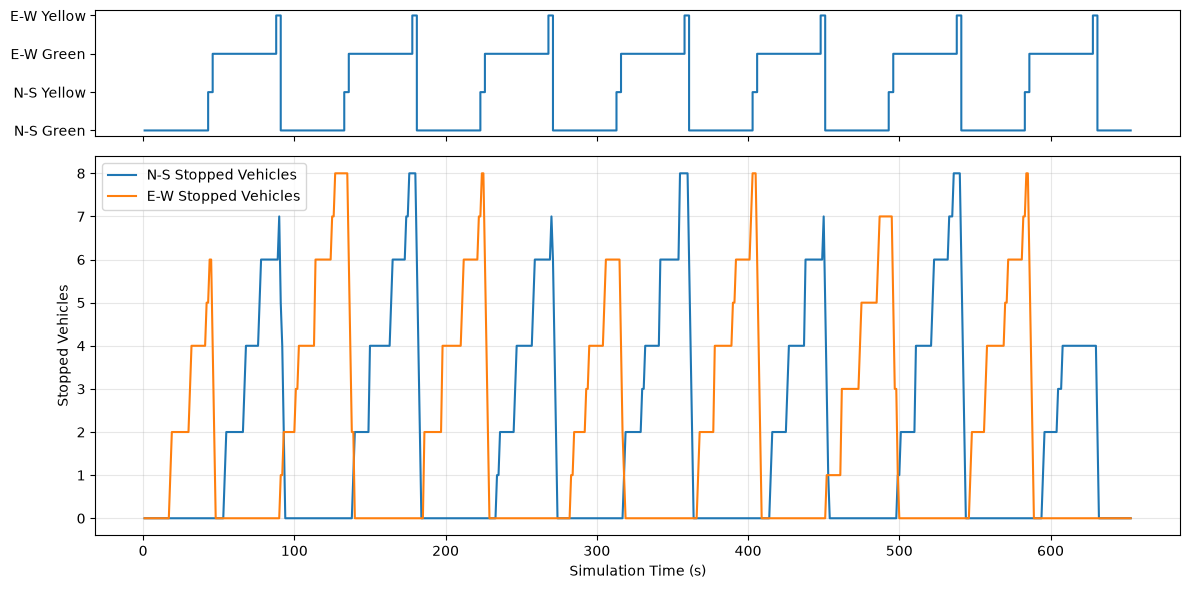

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 1, figsize=(12, 6),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 3]}
)

axes[0].step(
    df_signal["time"],
    df_signal["phase"],
    where="post"
)
axes[0].set_yticks([0, 1, 2, 3])
axes[0].set_yticklabels([
    "N-S Green",
    "N-S Yellow",
    "E-W Green",
    "E-W Yellow"
])

axes[1].plot(
    df_signal["time"],
    df_signal["NS_waiting"],
    label="N-S Stopped Vehicles"
)
axes[1].plot(
    df_signal["time"],
    df_signal["EW_waiting"],
    label="E-W Stopped Vehicles"
)

axes[1].set_xlabel("Simulation Time (s)")
axes[1].set_ylabel("Stopped Vehicles")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()